In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
file_path = "../data/US_Superstore_data.xls"

df = pd.read_excel(
    file_path,
    engine="xlrd"
)

print("Dataset loaded successfully.")
print("Original shape:", df.shape)

# Display columns
print("\nColumns:")
print(df.columns.tolist())

# Remove completely empty rows/columns
df.dropna(how="all", inplace=True)
df.dropna(axis=1, how="all", inplace=True)

# Remove duplicate rows
duplicates = df.duplicated().sum()
df.drop_duplicates(inplace=True)

# Convert date columns
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")

# Create time-based columns
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)

print("\nCleaning completed.")
print("Duplicate rows removed:", duplicates)
print("Final shape:", df.shape)

display(df.head())

C:\Users\tuntun'\AppData\Local\Temp\ipykernel_13996\1495338980.py:9: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(


Dataset loaded successfully.
Original shape: (9994, 21)

Columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Cleaning completed.
Duplicate rows removed: 0
Final shape: (9994, 25)


C:\Users\tuntun'\AppData\Local\Temp\ipykernel_13996\1495338980.py:22: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(how="all", inplace=True)
C:\Users\tuntun'\AppData\Local\Temp\ipykernel_13996\1495338980.py:23: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(axis=1, how="all", inplace=True)
C:\Users\tuntun'\AppData\Local\Temp\ipykernel_13996\1495338980.py:27: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Name,Year-Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November,2016-11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November,2016-11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June,2016-06
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October,2015-10
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October,2015-10


In [8]:
print("Missing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

print("\nDuplicate Rows After Cleaning:", df.duplicated().sum())

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Year             0
Month            0
Month Name       0
Year-Month       0
dtype: int64

Data Types:
Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code               int64
Region                      str
Product ID                  str
Category                    str
Sub

In [9]:
print("\nBasic Statistics:")
display(df.describe())


Basic Statistics:


,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,Year,Month
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355,2016-05-03 23:06:58.571142,55190.379428,229.858001,3.789574,0.156203,28.656896,2015.722233,7.809686
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000,2014.000000,1.000000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750,2015.000000,5.000000
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500,2016.000000,9.000000
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000,2017.000000,11.000000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000,2017.000000,12.000000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108,1.123555,3.284654


In [10]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_quantity = df["Quantity"].sum()

print("===== KEY PERFORMANCE INDICATORS =====")
print(f"Total Sales   : ${total_sales:,.2f}")
print(f"Total Profit  : ${total_profit:,.2f}")
print(f"Total Orders  : {total_orders:,}")
print(f"Total Quantity: {total_quantity:,}")

===== KEY PERFORMANCE INDICATORS =====
Total Sales   : $2,297,200.86
Total Profit  : $286,397.02
Total Orders  : 5,009
Total Quantity: 37,873


In [11]:
profit_margin = (total_profit / total_sales) * 100

print(f"Profit Margin: {profit_margin:.2f}%")

Profit Margin: 12.47%


In [12]:
region_analysis = (
    df.groupby("Region")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Sales", ascending=False)
)

display(region_analysis)

,Sales,Profit,Orders,Quantity
Region,,,,
West,725457.8245,108418.4489,1611,12266
East,678781.2400,91522.7800,1401,10618
Central,501239.8908,39706.3625,1175,8780
South,391721.9050,46749.4303,822,6209


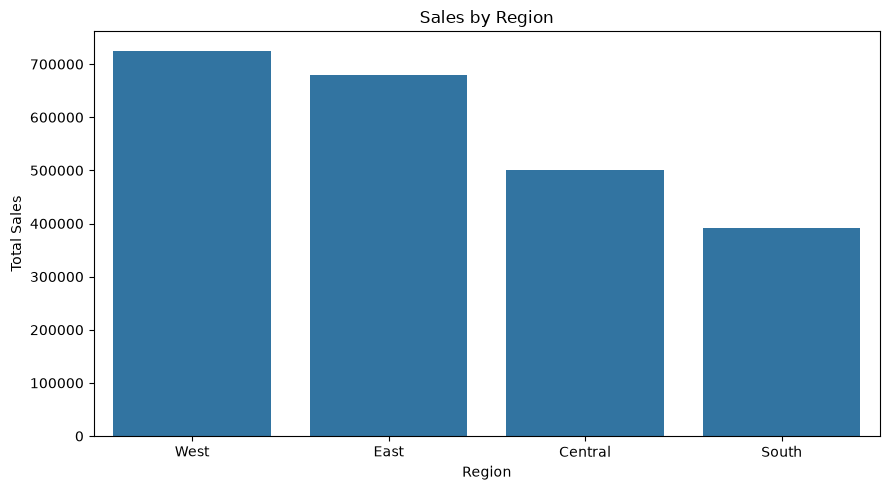

In [13]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Sales"
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
category_analysis = (
    df.groupby("Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Sales", ascending=False)
)

display(category_analysis)

,Sales,Profit,Orders,Quantity
Category,,,,
Technology,836154.0330,145454.9481,1544,6939
Furniture,741999.7953,18451.2728,1764,8028
Office Supplies,719047.0320,122490.8008,3742,22906


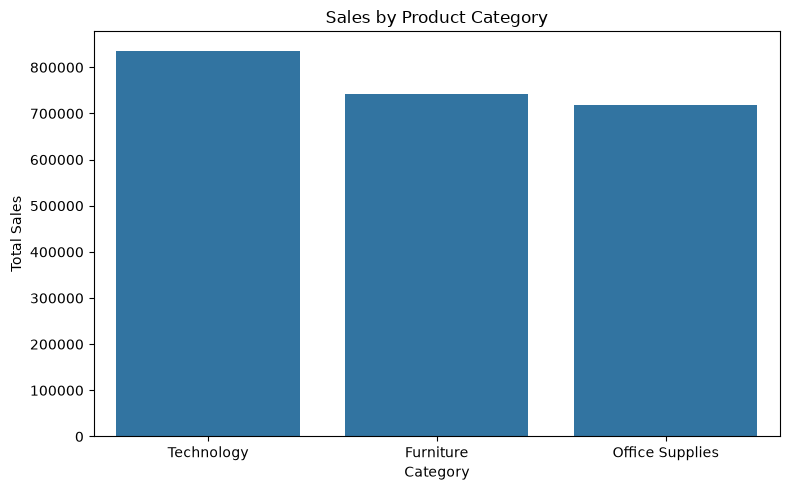

In [15]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=category_analysis.reset_index(),
    x="Category",
    y="Sales"
)

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [16]:
top_products = (
    df.groupby("Product Name")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Sales", ascending=False)
      .head(10)
)

display(top_products)

,Sales,Profit,Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7.753039e+03,31
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1.811078e+03,6
HON 5400 Series Task Chairs for Big and Tall,21870.576,3.979039e-13,39
GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03,37
GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02,48
Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03,38
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4.094977e+03,12
GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03,27


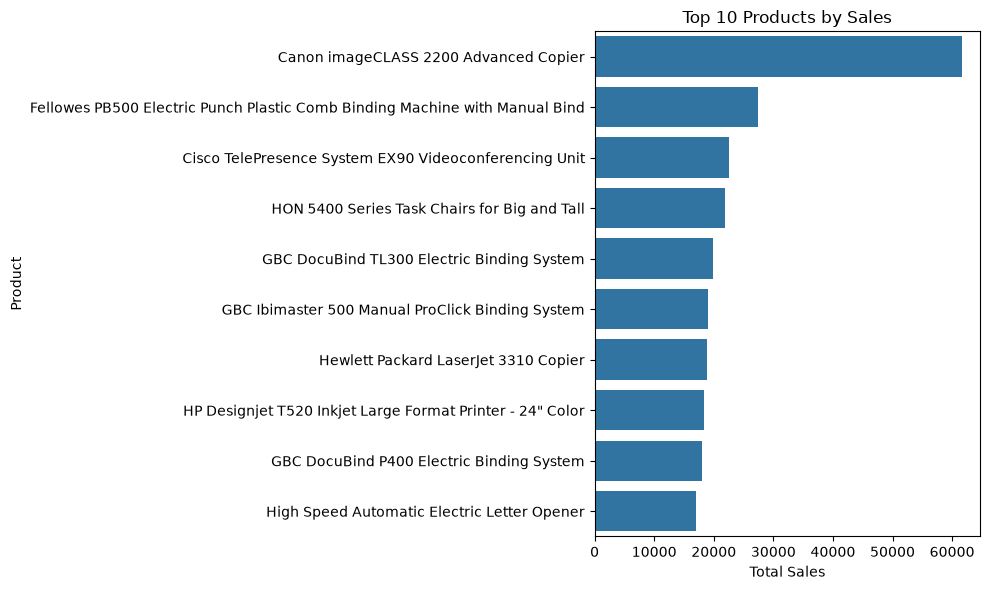

In [17]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_products.reset_index(),
    x="Sales",
    y="Product Name"
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [18]:
monthly_sales = (
    df.groupby("Year-Month")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
      .reset_index()
)

display(monthly_sales.head())

,Year-Month,Sales,Profit,Orders
0,2014-01,14236.895,2450.1907,32
1,2014-02,4519.892,862.3084,28
2,2014-03,55691.009,498.7299,71
3,2014-04,28295.345,3488.8352,66
4,2014-05,23648.287,2738.7096,69


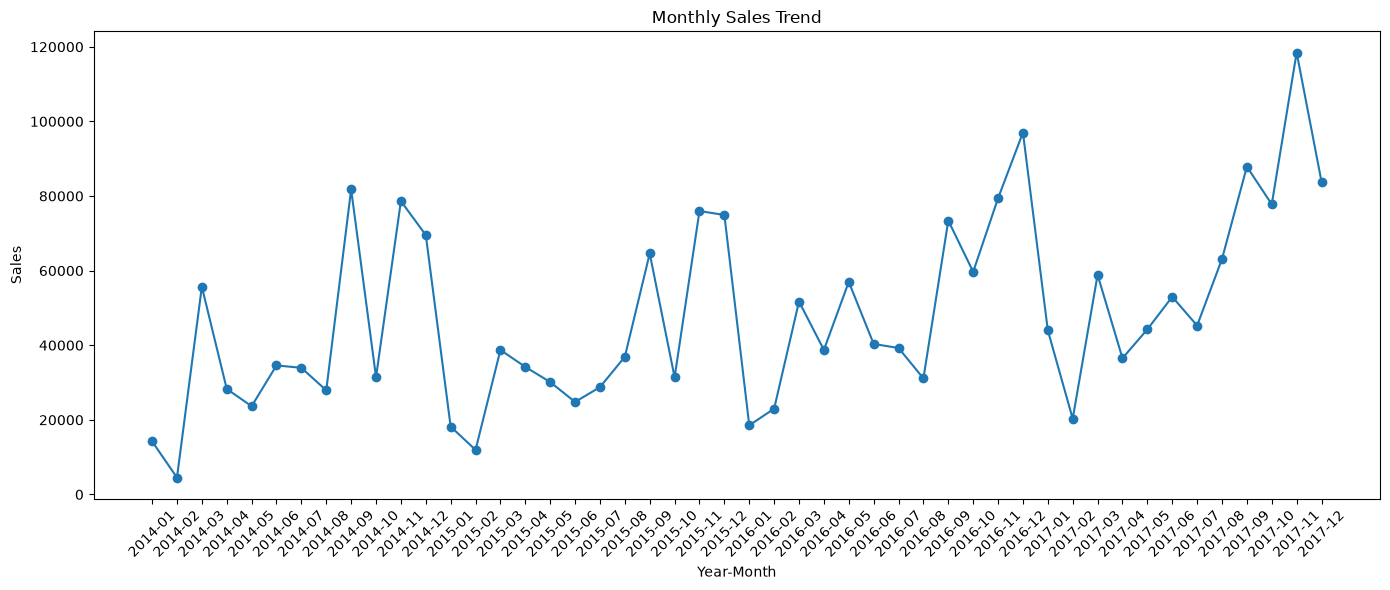

In [19]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
import sys

!{sys.executable} -m pip install plotly dash

  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached flask-3.1.3-py3-none-any.whl.metadata (3.2 kB)
  Using cached werkzeug-3.1.9-py3-none-any.whl.metadata (4.1 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached blinker-1.9.0-py3-none-any.whl.metadata (1.6 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
Using cached plotly-7.1.0-py3-none-any.whl (9.7 MB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 2.2 MB/s eta 0:00:04
   ------ --------------------------------- 1.6/9.3 MB 2.5 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.3 MB 2.5 MB/s eta 0:00:04
   ----------- ---------------------------- 2.6/9.3 MB 2.4 MB/s eta 0:00:03
   ------------- -------------------------- 3.1/9.3 M

In [21]:
plt.savefig("../visuals/sales_by_region.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [22]:
plt.savefig("../visuals/sales_by_category.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [23]:
plt.savefig("../visuals/monthly_sales_trend.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [24]:
plt.savefig("../visuals/top_10_products.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>